# SentraGrade: novelty maps that explain why an item was rejected

Grad-CAM shows where the evidence for the **guessed** class is. For a rejected item that answers the wrong question: an unseen banana gets a map of where it looks like guava. This notebook builds maps of **what looks unfamiliar** and tests whether they explain the rejection better.

**Maps compared** (all on a 16 × 16 grid of 14-pixel patches over the 224 × 224 crop):

| Map | Model | How it is made | Training |
|---|---|---|---|
| **Class-conditional novelty map (ours)** | DINOv2 ViT-S/14, frozen | Each patch is compared with stored training patches of the class the image is closest to (by its CLS token); heat = 1 − cosine similarity to the nearest such patch | none |
| Unconditional patch map (AnomalyDINO-style baseline) | DINOv2, frozen | Same, but against the pooled patches of all known classes | none |
| **Energy-CAM** | ResNet50 from the leakage notebook | Grad-CAM weights from the gradient of the energy score instead of the predicted-class logit | uses saved checkpoints |
| Grad-CAM (current explainer) | ResNet50 | Gradient of the predicted-class logit at `layer4` | uses saved checkpoints |
| Random, centre prior | none | Sanity baselines | none |

**Tests**
1. **Detection:** image-level AUROC / FPR@95 of three frozen-DINOv2 scores: CLS-prototype distance, unconditional patch score, class-conditional patch score.
2. **Faithfulness**, run only on held-out images the target model actually **rejects** (score above the 95th percentile of known validation scores):
   - **Deletion:** blur the hottest patches first, up to 25% of the image. A faithful map makes the OOD score fall fastest (lower AUC).
   - **Insertion:** start from a fully blurred image and restore the hottest patches first. A faithful map makes the OOD score rise fastest (higher AUC).
   - The score tracked is never the one the map is built from: the DINOv2 **CLS-prototype distance** and the ResNet **energy**. Curves are normalised so 1 = the original image and 0 = a typical known test image, and summarised by the **median** over images.
3. **Map spread** (hot-area fraction, normalised entropy) for known vs unknown images.
4. **Triage** (needs `spoilage_labels.csv`): banks built from **fresh** training produce only, then spread and scores compared for fresh known, spoiled known, unknown fresh, unknown spoiled and foreign objects.

**Split:** the leakage-corrected **stage-matched** split from `leakage_split_resnet50.ipynb`, rebuilt here with the same code (fresh days and spoiled days are time-blocked separately, so train, val and test all contain both). The notebook checks the rebuilt split against the attached ResNet checkpoints.

**Far-OOD (foreign objects):** instead of hand-collected photos, two public image sets are sampled automatically:
- **COIL-100** (Nene et al., 1996): 100 everyday objects on a plain background; 3 views of each object = 300 images.
- **DTD** (Cimpoi et al., 2014): the Describable Textures Dataset, a standard far-OOD set; ~300 images spread over all 47 texture categories (test split).
- your own photos, if a folder with `foreign` in its path is attached (optional).

These come from different cameras and backgrounds than TR-6, so they are **far-OOD** (clearly not produce). The held-out fruit stays the **near-OOD** case.

**Kaggle inputs**
- `sentragrade_data.zip` (required)
- the output of `leakage_split_resnet50.ipynb` (optional; enables Grad-CAM and Energy-CAM)
- `spoilage_labels.csv` as a small dataset (optional; enables the triage section)
- the **COIL-100** dataset (Add Input → search "coil100"; recommended)
- DTD downloads automatically through torchvision (needs Internet)
- a folder of your own foreign-object photos whose path contains `foreign` (optional)

Turn on **GPU** and **Internet**. Run All, about 30 to 50 min on a T4.

In [1]:
import os, re, glob, json, math, time, random, shutil
from pathlib import Path
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision.transforms.functional as TF
from torchvision.models import resnet50
from PIL import Image
from sklearn.metrics import roc_auc_score
from scipy.stats import wilcoxon
import timm
import matplotlib.pyplot as plt

# ---------------- config ----------------
SEED = 42
CLASSES = ["Banana", "Carrot", "Guava", "Indian_Gooseberry", "Mango", "Tomato"]
FOLDS = list(range(6))
SPLIT_MODE = "stage_matched"      # must match leakage_split_resnet50.ipynb
SPLIT_DIRECTION, TRAIN_FRAC, BUFFER_DAYS = "forward", 0.60, 1   # must match leakage_split_resnet50.ipynb
FAR_OOD_N = 300                   # images sampled from each public far-OOD set (COIL-100, DTD)
SESSION_GAP_MIN = 5
G, PATCH = 16, 14                 # 16 x 16 patches of 14 px on a 224 crop
BANK_PER_CLASS = 30000            # training patches kept per known class
TOPK = 3                          # image score = mean of the top 1% (3 of 256) patch scores
N_DEL = 60                        # rejected held-out images per fold and target used in the faithfulness tests
DEL_STEP, DEL_MAX = 4, 64         # deletion: blur 0, 4, ..., 64 patches (up to 25% of the image)
INS_STEP = 16                     # insertion: restore 0, 16, ..., 256 patches
FILL = "blur"                     # "blur" (default) or "background" (border colour; creates artefacts)
N_BOOT = 1000
N_FIG = 4
QUICK = False                     # True = tiny subsets for a smoke test

INPUT = Path("/kaggle/input") if Path("/kaggle/input").exists() else None
def find_data_root():
    if os.environ.get("SENTRAGRADE_DATA_ROOT"):
        return Path(os.environ["SENTRAGRADE_DATA_ROOT"])
    hits = glob.glob(f"{INPUT}/**/manifest_full.csv", recursive=True) if INPUT else []
    return Path(hits[0]).parent if hits else Path("~/sentragrade_data").expanduser()
DATA_ROOT = find_data_root()

CKPT_ROOT = os.environ.get("CKPT_ROOT", str(INPUT) if INPUT else "outputs")
CKPTS = {int(re.search(r"fold(\d)", p).group(1)): p
         for p in glob.glob(f"{CKPT_ROOT}/**/resnet50_corrected_fold*.pt", recursive=True)}

def find_spoil():
    if os.environ.get("SPOIL_CSV"):
        return os.environ["SPOIL_CSV"]
    hits = glob.glob(f"{INPUT}/**/spoilage_labels.csv", recursive=True) if INPUT else []
    hits += [p for p in ["spoilage_labels.csv", "kaggle/spoilage_labels.csv"] if os.path.exists(p)]
    return hits[0] if hits else None
SPOIL_CSV = find_spoil()

EXTS = (".jpg", ".jpeg", ".png", ".webp")
def images_under(root):
    return sorted(p for p in glob.glob(str(root) + "/**/*", recursive=True) if p.lower().endswith(EXTS))

# own photos (optional)
if os.environ.get("FOREIGN_DIR"):
    OWN = images_under(os.environ["FOREIGN_DIR"])
elif INPUT:
    OWN = [p for p in images_under(INPUT) if "foreign" in p.lower() and "coil" not in p.lower()]
else:
    OWN = []

# COIL-100: 3 evenly spaced views of every object (file names look like obj12__145.png)
def sample_coil():
    root = os.environ.get("COIL_DIR")
    pool = images_under(root) if root else ([p for p in images_under(INPUT) if "coil" in p.lower()] if INPUT else [])
    by_obj = {}
    for q in pool:
        m = re.search(r"obj(\d+)__(\d+)", os.path.basename(q))
        if m:
            by_obj.setdefault(int(m.group(1)), []).append((int(m.group(2)), q))
    if not by_obj:
        rng = np.random.default_rng(SEED)
        return sorted(rng.choice(pool, size=min(FAR_OOD_N, len(pool)), replace=False).tolist()) if pool else []
    per = max(1, FAR_OOD_N // len(by_obj)); out = []
    for o in sorted(by_obj):
        views = [q for _, q in sorted(set(by_obj[o]))]
        out += [views[int(i)] for i in np.linspace(0, len(views) - 1, per, endpoint=False).round().astype(int)]
    return out[:FAR_OOD_N]

# DTD: test split, sampled evenly across the 47 texture categories
def sample_dtd():
    root = os.environ.get("DTD_DIR")
    if not root:
        try:
            from torchvision.datasets import DTD
            dl_root = "/tmp/dtd" if INPUT else "outputs/dtd"
            ds = DTD(dl_root, split="test", download=True)
            pool = [str(f) for f in ds._image_files]
        except Exception as e:
            print("DTD download failed (is Internet on?):", repr(e)[:200]); return []
    else:
        pool = images_under(root)
    by_cat = {}
    for q in pool:
        by_cat.setdefault(Path(q).parent.name, []).append(q)
    rng = np.random.default_rng(SEED)
    per = int(np.ceil(FAR_OOD_N / max(1, len(by_cat)))); out = []
    for c in sorted(by_cat):
        out += sorted(rng.choice(by_cat[c], size=min(per, len(by_cat[c])), replace=False).tolist())
    return sorted(rng.choice(out, size=min(FAR_OOD_N, len(out)), replace=False).tolist())

FAR = {"own_photos": OWN, "coil100": sample_coil(), "dtd": sample_dtd()}
FAR = {k: v for k, v in FAR.items() if v}
FOREIGN = [q for v in FAR.values() for q in v]
FOREIGN_SRC = np.array([k for k, v in FAR.items() for _ in v])

OUT = Path("/kaggle/working/sentragrade_novelty") if Path("/kaggle/working").exists() else Path("outputs/sentragrade_novelty")
OUT.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
BANK_DTYPE = torch.float16 if DEVICE.type == "cuda" else torch.float32
NUM_WORKERS = 2 if DEVICE.type == "cuda" else 0
TRAPZ = getattr(np, "trapezoid", None) or np.trapz
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
set_seed(SEED)
if QUICK:
    FOLDS, BANK_PER_CLASS, N_DEL, N_BOOT, N_FIG = [0], 2000, 4, 50, 2
print("data:", DATA_ROOT, "| device:", DEVICE, "| ResNet checkpoints for folds:", sorted(CKPTS),
      "| far-OOD images:", {k: len(v) for k, v in FAR.items()}, "| spoilage labels:", SPOIL_CSV)
assert SPLIT_MODE == "time_blocked" or SPOIL_CSV, "spoilage_labels.csv is needed for the stage-matched split"
if "coil100" not in FAR:
    print("NOTE: COIL-100 not found. Add Input -> search 'coil100' to include it.")
assert (DATA_ROOT / "manifest_full.csv").exists(), "attach sentragrade_data.zip"

100%|██████████| 625M/625M [00:15<00:00, 40.7MB/s]


data: /kaggle/input/datasets/riteesh23f3002667/sentragrade-data/sentragrade_data | device: cuda | ResNet checkpoints for folds: [0, 1, 2, 3, 4, 5] | far-OOD images: {'coil100': 300, 'dtd': 300} | spoilage labels: /kaggle/input/datasets/riteesh23f3002667/sentragrade-data/spoilage_labels.csv


## 1. Rebuild the leakage-corrected split

In [2]:
man = pd.read_csv(DATA_ROOT / "manifest_full.csv", dtype={"date": str, "time": str})
man["path"] = [str(DATA_ROOT / "resized" / c / f) for c, f in zip(man.class_name, man.filename)]
man["ts"] = pd.to_datetime(man.date + man.time.str.zfill(6), format="%Y%m%d%H%M%S")
man = man.sort_values(["class_name", "ts"]).reset_index(drop=True)
gap = man.groupby("class_name").ts.diff() > pd.Timedelta(minutes=SESSION_GAP_MIN)
man["session"] = man.class_name + "_" + gap.groupby(man.class_name).cumsum().astype(str)
man = man.drop(columns=[c for c in ["spoil_status"] if c in man])
if SPOIL_CSV:
    man = man.merge(pd.read_csv(SPOIL_CSV)[["class_name", "filename", "spoil_status"]], on=["class_name", "filename"], how="left")
    print("spoilage labels missing for", man.spoil_status.isna().sum(), "images")
else:
    man["spoil_status"] = np.nan

def blocked_split(d):
    # whole capture days, in time order: train block, buffer day(s) dropped, then val and test blocks.
    # Small blocks (a stage with only 2-4 days) degrade gracefully: the buffer is skipped when it would
    # leave fewer than 2 days, and 2 days give train + test with no val.
    days = sorted(d.date.unique(), reverse=(SPLIT_DIRECTION == "reverse"))
    if len(days) == 1:
        return days, [], [], []
    if len(days) == 2:
        return days[:1], [], [], days[1:]
    n = d.groupby("date").size().reindex(days).values
    cum = np.cumsum(n) / n.sum()
    n_tr = int(np.clip((cum <= TRAIN_FRAC).sum(), 1, len(days) - 2))
    buf_n = BUFFER_DAYS if len(days) - n_tr - BUFFER_DAYS >= 2 else 0
    rest = days[n_tr + buf_n:]
    k = max(1, len(rest) // 2)
    return days[:n_tr], days[n_tr:n_tr + buf_n], rest[:k], rest[k:]

def split_class(d):
    if SPLIT_MODE == "time_blocked":
        return blocked_split(d)
    # stage-matched: every capture day is all fresh or all spoiled (checked), block each stage separately
    stage_of_day = d.groupby("date").spoil_status.agg(lambda x: x.mode().iloc[0])
    mixed = d.groupby("date").spoil_status.nunique()
    assert (mixed == 1).all(), f"{d.class_name.iloc[0]}: some days mix fresh and spoiled images"
    out = [[], [], [], []]
    for st in sorted(stage_of_day.unique()):
        part = blocked_split(d[d.date.isin(stage_of_day[stage_of_day == st].index)])
        for i in range(4):
            out[i] += list(part[i])
    return tuple(sorted(x) for x in out)

split_days = {c: dict(zip(["train", "buffer", "val", "test"], split_class(d))) for c, d in man.groupby("class_name")}

def get_fold(k):
    held = CLASSES[k]
    known = sorted(c for c in CLASSES if c != held)
    kn = man[man.class_name != held]
    pick = lambda part: pd.concat([kn[(kn.class_name == c) & kn.date.isin(split_days[c][part])] for c in known])
    f = dict(train=pick("train"), val=pick("val"), test=pick("test"), ood=man[man.class_name == held],
             known=known, held=held)
    if QUICK:
        f["train"] = f["train"].groupby("class_name").head(30); f["val"] = f["val"].groupby("class_name").head(10)
        f["test"] = f["test"].groupby("class_name").head(10); f["ood"] = f["ood"].head(20)
    return f

FOLD = {k: get_fold(k) for k in FOLDS}
# check the rebuilt split against the ResNet checkpoints from the leakage notebook
for k in FOLDS:
    if k in CKPTS and not QUICK:
        ck = torch.load(CKPTS[k], map_location="cpu", weights_only=False)
        mode = ck.get("split_mode", "time_blocked")
        n_ck = (len(ck["train"]["labels"]), len(ck["val"]["labels"]), len(ck["test"]["labels"]))
        n_me = (len(FOLD[k]["train"]), len(FOLD[k]["val"]), len(FOLD[k]["test"]))
        assert mode == SPLIT_MODE and n_ck == n_me, (f"fold {k}: checkpoint split ({mode}, train/val/test {n_ck}) differs from "
                                                     f"this notebook ({SPLIT_MODE}, {n_me}). Attach the new leakage-notebook output.")
        del ck
if CKPTS:
    print("split matches the ResNet checkpoints" if not QUICK else "(QUICK: checkpoint split check skipped)")
for k, f in FOLD.items():
    print(f"fold {k} ({f['held']}): train {len(f['train'])}  val {len(f['val'])}  test {len(f['test'])}  held-out {len(f['ood'])}")
if SPOIL_CSV:
    blk = pd.concat([FOLD[FOLDS[0]][p].assign(block=p) for p in ["train", "val", "test"]])
    print("Spoilage mix per block (first fold's known classes):")
    display(pd.crosstab([blk.class_name, blk.block], blk.spoil_status))

spoilage labels missing for 0 images
split matches the ResNet checkpoints
fold 0 (Banana): train 2805  val 953  test 1003  held-out 323
fold 1 (Carrot): train 2669  val 1004  test 1003  held-out 458
fold 2 (Guava): train 2669  val 953  test 1003  held-out 510
fold 3 (Indian_Gooseberry): train 2091  val 817  test 867  held-out 1411
fold 4 (Mango): train 2737  val 952  test 1003  held-out 392
fold 5 (Tomato): train 1649  val 596  test 646  held-out 2244
Spoilage mix per block (first fold's known classes):


spoil_status             Not_spoiled  Spoiled
class_name        block                      
Carrot            test            51       51
                  train           51      204
                  val              0       51
Guava             test            51       51
                  train          102      153
                  val             51       51
Indian_Gooseberry test           170       68
                  train          527      306
                  val            136      102
Mango             test            51       51
                  train          153       34
                  val             52       51
Tomato            test           408       51
                  train         1207       68
                  val            408       51

## 2. Frozen DINOv2 features for every image (computed once, shared by all folds)

In [3]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
eval_tf = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224),
                              transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class Paths(Dataset):
    def __init__(self, paths): self.paths = list(paths)
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        with Image.open(self.paths[i]) as im:
            return eval_tf(im.convert("RGB"))
def load_imgs(paths):
    ds = Paths(paths)
    return torch.stack([ds[i] for i in range(len(ds))])

dino = timm.create_model("vit_small_patch14_dinov2.lvd142m", pretrained=True, img_size=224, num_classes=0).to(DEVICE).eval()
NPRE = dino.num_prefix_tokens
assert tuple(dino.patch_embed.grid_size) == (G, G)

@torch.no_grad()
def dino_feats(x):
    t = dino.forward_features(x.to(DEVICE))
    return F.normalize(t[:, 0].float(), dim=-1), F.normalize(t[:, NPRE:].float(), dim=-1)

need = sorted(set().union(*[set(pd.concat([f["train"], f["val"], f["test"], f["ood"]]).path) for f in FOLD.values()]))
need += [p for p in FOREIGN if p not in need]
ROW = {p: i for i, p in enumerate(need)}
CLS = np.zeros((len(need), 384), np.float32)
PT = np.zeros((len(need), G * G, 384), np.float16)
dl = DataLoader(Paths(need), batch_size=64, num_workers=NUM_WORKERS)
i0, t0 = 0, time.time()
for x in dl:
    c, p = dino_feats(x)
    CLS[i0:i0 + len(x)] = c.cpu().numpy(); PT[i0:i0 + len(x)] = p.cpu().numpy().astype(np.float16)
    i0 += len(x)
print(f"features for {len(need)} images in {time.time()-t0:.0f}s; patch array {PT.nbytes/1e9:.2f} GB")

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

features for 5938 images in 112s; patch array 1.17 GB


## 3. Patch banks, scores and maps

In [4]:
def build_bank(train_df, known):
    g = torch.Generator().manual_seed(SEED)
    protos, banks = [], []
    for c in known:
        idx = [ROW[p] for p in train_df.path[train_df.class_name == c]]
        assert idx, f"no bank images for {c}"
        protos.append(F.normalize(torch.from_numpy(CLS[idx]).mean(0), dim=0))
        P = torch.from_numpy(PT[idx].reshape(-1, 384))
        sel = torch.randperm(len(P), generator=g)[:BANK_PER_CLASS]
        banks.append(P[sel].to(DEVICE, BANK_DTYPE))
    return torch.stack(protos).to(DEVICE), banks

def score_feats(cls, pt, protos, banks):
    B = pt.shape[0]
    sim_cls = cls.to(DEVICE) @ protos.T
    cstar = sim_cls.argmax(1)                                   # class the image is closest to
    q = pt.reshape(-1, pt.shape[-1]).to(DEVICE, BANK_DTYPE)
    best = torch.stack([(q @ b.T).max(1).values.float() for b in banks], 1).reshape(B, G * G, -1)
    uncond = 1 - best.max(2).values                             # nearest patch of any known class
    cond = 1 - best.gather(2, cstar.view(B, 1, 1).expand(B, G * G, 1)).squeeze(2)   # nearest patch of class c*
    top = lambda m: m.topk(TOPK, dim=1).values.mean(1)
    return {"cls": (1 - sim_cls.max(1).values).cpu(), "uncond": top(uncond).cpu(), "cond": top(cond).cpu(),
            "map_cond": cond.reshape(B, G, G).cpu(), "map_uncond": uncond.reshape(B, G, G).cpu(), "cstar": cstar.cpu()}

def score_rows(paths, protos, banks, bs=16):
    paths = list(paths); out = []
    for s in range(0, len(paths), bs):
        idx = [ROW[p] for p in paths[s:s + bs]]
        out.append(score_feats(torch.from_numpy(CLS[idx]), torch.from_numpy(PT[idx].astype(np.float32)), protos, banks))
    return {k: torch.cat([o[k] for o in out]) for k in out[0]}

def spread(maps, tau, med):
    hot = (maps > tau).float().mean((1, 2))
    ex = (maps - med).clamp(min=0).flatten(1)
    s = ex.sum(1, keepdim=True)
    p = ex / s.clamp(min=1e-12)
    ent = -(p * (p + 1e-12).log()).sum(1) / math.log(G * G)
    ent[s.squeeze(1) == 0] = 1.0
    return hot.numpy(), ent.numpy()

def fpr95(neg, pos): return float((neg >= np.percentile(pos, 5)).mean())
def auroc(neg, pos): return roc_auc_score(np.r_[np.zeros(len(neg)), np.ones(len(pos))], np.r_[neg, pos])
def boot_auroc(neg, pos, ns, ps, rng):
    a_ = pd.Series(neg).groupby(ns).apply(np.array).values; b_ = pd.Series(pos).groupby(ps).apply(np.array).values
    out = []
    for _ in range(N_BOOT):
        a = np.concatenate(a_[rng.integers(0, len(a_), len(a_))]); b = np.concatenate(b_[rng.integers(0, len(b_), len(b_))])
        out.append(auroc(a, b))
    return np.percentile(out, [2.5, 97.5])

## 4. ResNet50 Grad-CAM and Energy-CAM (only if the leakage-notebook checkpoints are attached)

In [5]:
class ResNetClassifier(nn.Module):
    def __init__(self, n):
        super().__init__()
        b = resnet50(weights=None)
        self.stem = nn.Sequential(b.conv1, b.bn1, b.relu, b.maxpool)
        self.layer1, self.layer2, self.layer3, self.layer4 = b.layer1, b.layer2, b.layer3, b.layer4
        self.avgpool, self.fc = b.avgpool, nn.Linear(b.fc.in_features, n)
    def forward(self, x):
        x = self.layer4(self.layer3(self.layer2(self.layer1(self.stem(x)))))
        f = torch.flatten(self.avgpool(x), 1)
        return self.fc(f), f

def load_resnet(k):
    if k not in CKPTS:
        return None
    ck = torch.load(CKPTS[k], map_location="cpu", weights_only=False)
    if ck.get("split_direction", "forward") != SPLIT_DIRECTION:
        print(f"WARNING fold {k}: checkpoint split_direction={ck.get('split_direction')} differs from {SPLIT_DIRECTION}")
    m = ResNetClassifier(len(ck["label_map"])); m.load_state_dict(ck["model_state_dict"])
    return m.to(DEVICE).eval()

def resnet_cams(model, x, bs=16):
    gcs, ecs = [], []
    for s in range(0, len(x), bs):
        acts = {}
        h = model.layer4.register_forward_hook(lambda mod, i, o: acts.__setitem__("a", o))
        with torch.enable_grad():
            logits, _ = model(x[s:s + bs].to(DEVICE))
            A = acts["a"]
            pred = logits.argmax(1)
            g_cls, = torch.autograd.grad(logits.gather(1, pred[:, None]).sum(), A, retain_graph=True)
            g_en, = torch.autograd.grad((-torch.logsumexp(logits, 1)).sum(), A)   # channels that push energy up
        h.remove()
        cam = lambda g: F.relu((g.mean((2, 3), keepdim=True) * A).sum(1)).detach()
        up = lambda c: F.interpolate(c[:, None], size=(G, G), mode="bilinear", align_corners=False)[:, 0].cpu()
        gcs.append(up(cam(g_cls))); ecs.append(up(cam(g_en)))
    return torch.cat(gcs), torch.cat(ecs)

@torch.no_grad()
def resnet_energy(model, x, bs=64):
    return torch.cat([-torch.logsumexp(model(x[s:s + bs].to(DEVICE))[0], 1).cpu() for s in range(0, len(x), bs)])

@torch.no_grad()
def resnet_energy_paths(model, paths):
    out = []
    for x in DataLoader(Paths(paths), batch_size=64, num_workers=NUM_WORKERS):
        out.append(-torch.logsumexp(model(x.to(DEVICE))[0], 1).cpu())
    return torch.cat(out).numpy()

## 5. Faithfulness tests: deletion and insertion

In [6]:
yy, xx = torch.meshgrid(torch.arange(G), torch.arange(G), indexing="ij")
CENTRE = torch.exp(-((yy - (G - 1) / 2) ** 2 + (xx - (G - 1) / 2) ** 2) / (2 * 4.0 ** 2))
STEPS = {"deletion": list(range(0, DEL_MAX + 1, DEL_STEP)), "insertion": list(range(0, G * G + 1, INS_STEP))}

def baseline(x):
    if FILL == "blur":
        return TF.gaussian_blur(x[None], kernel_size=51, sigma=16)[0]
    border = torch.cat([x[:, 0, :], x[:, -1, :], x[:, :, 0], x[:, :, -1]], 1)
    return border.median(1).values[:, None, None].expand_as(x)

def perturb(x, heat, mode):
    # deletion: hottest patches replaced by the blurred image; insertion: blurred image with hottest patches restored
    base = baseline(x)
    order = heat.flatten().argsort(descending=True)
    out = []
    for n in STEPS[mode]:
        m = torch.zeros(G * G); m[order[:n]] = 1
        M = F.interpolate(m.view(1, 1, G, G), scale_factor=PATCH, mode="nearest")[0]
        out.append(x * (1 - M) + base * M if mode == "deletion" else base * (1 - M) + x * M)
    return torch.stack(out)

@torch.no_grad()
def target_dino_cls(xb, protos):
    c, _ = dino_feats(xb)
    return (1 - (c @ protos.T).max(1).values).cpu()

def norm_curve(s, s_orig, ref):
    # 1 = as unfamiliar as the untouched image, 0 = as familiar as a typical known test image
    return ((s - ref) / (s_orig - ref)).numpy()

## 6. Run every fold

In [7]:
det_rows, img_rows, faith_rows, curves, fig_items = [], [], [], [], []
for k in FOLDS:
    f = FOLD[k]; t0 = time.time()
    protos, banks = build_bank(f["train"], f["known"])
    S = {part: score_rows(f[part].path, protos, banks) for part in ["val", "test", "ood"]}
    if FOREIGN:
        S["foreign"] = score_rows(FOREIGN, protos, banks)
    rng = np.random.default_rng(SEED)
    # --- detection ---
    for m in ["cls", "uncond", "cond"]:
        neg, pos = S["test"][m].numpy(), S["ood"][m].numpy()
        lo, hi = boot_auroc(neg, pos, f["test"].session.values, f["ood"].session.values, rng)
        row = {"fold": k, "held_out": f["held"], "score": m, "AUROC": auroc(neg, pos),
               "AUROC_lo": lo, "AUROC_hi": hi, "FPR95": fpr95(neg, pos)}
        if FOREIGN:
            fs = S["foreign"][m].numpy()
            row["AUROC_vs_far_all"] = auroc(neg, fs)
            row["FPR95_vs_far_all"] = fpr95(neg, fs)
            for src in FAR:
                row[f"AUROC_vs_{src}"] = auroc(neg, fs[FOREIGN_SRC == src])
                row[f"FPR95_vs_{src}"] = fpr95(neg, fs[FOREIGN_SRC == src])
        det_rows.append(row)
    # --- per-image spread of the novelty map ---
    vm = S["val"]["map_cond"]
    tau, med = torch.quantile(vm.flatten(), 0.99).item(), vm.median().item()
    groups = [("known_test", f["test"], "test"), ("unknown_fruit", f["ood"], "ood")]
    for gname, df, part in groups:
        hot, ent = spread(S[part]["map_cond"], tau, med)
        for i, r in enumerate(df.itertuples()):
            img_rows.append({"fold": k, "group": gname, "class": r.class_name, "spoil_status": r.spoil_status, "path": r.path,
                             "closest_known": f["known"][S[part]["cstar"][i]], "score_cls": S[part]["cls"][i].item(),
                             "score_uncond": S[part]["uncond"][i].item(), "score_cond": S[part]["cond"][i].item(),
                             "hot_frac": hot[i], "entropy": ent[i]})
    if FOREIGN:
        hot, ent = spread(S["foreign"]["map_cond"], tau, med)
        for i, p in enumerate(FOREIGN):
            img_rows.append({"fold": k, "group": "foreign", "class": FOREIGN_SRC[i], "path": p, "score_cls": S["foreign"]["cls"][i].item(),
                             "score_uncond": S["foreign"]["uncond"][i].item(), "score_cond": S["foreign"]["cond"][i].item(),
                             "hot_frac": hot[i], "entropy": ent[i]})
    np.savez_compressed(OUT / f"novelty_maps_fold{k}.npz",
                        **{f"{part}_cond": S[part]["map_cond"].half().numpy() for part in S},
                        **{f"{part}_uncond": S[part]["map_uncond"].half().numpy() for part in S})
    # --- faithfulness: only held-out images the target model rejects ---
    resnet = load_resnet(k)
    targets = {"dino_cls": dict(fn=lambda xb: target_dino_cls(xb, protos),
                                ref=S["test"]["cls"].median().item(),
                                rejected=np.where(S["ood"]["cls"].numpy() > np.percentile(S["val"]["cls"].numpy(), 95))[0])}
    if resnet is not None:
        e_val, e_test, e_ood = (resnet_energy_paths(resnet, f[p].path.tolist()) for p in ["val", "test", "ood"])
        targets["resnet_energy"] = dict(fn=lambda xb: resnet_energy(resnet, xb), ref=float(np.median(e_test)),
                                        rejected=np.where(e_ood > np.percentile(e_val, 95))[0])
    for tname, T in targets.items():
        n_rej = len(T["rejected"])
        print(f"  {tname}: {n_rej}/{len(f['ood'])} held-out images rejected")
        if n_rej == 0:
            continue
        idx = np.random.default_rng(SEED + k).choice(T["rejected"], size=min(N_DEL, n_rej), replace=False)
        paths = f["ood"].path.values[idx].tolist()
        X = load_imgs(paths)
        maps = {"novelty_cond": S["ood"]["map_cond"][idx], "novelty_uncond": S["ood"]["map_uncond"][idx],
                "random": torch.rand(len(idx), G, G, generator=torch.Generator().manual_seed(SEED + k)),
                "centre": CENTRE.expand(len(idx), G, G)}
        if resnet is not None:
            maps["gradcam"], maps["energycam"] = resnet_cams(resnet, X)
        s_orig = T["fn"](X)
        for i in range(len(idx)):
            for mname, mm in maps.items():
                for mode in ["deletion", "insertion"]:
                    c = norm_curve(T["fn"](perturb(X[i], mm[i], mode)), s_orig[i], T["ref"])
                    faith_rows.append({"fold": k, "held_out": f["held"], "target": tname, "test": mode, "map": mname,
                                       "image": paths[i], "auc": float(TRAPZ(c, dx=1 / (len(c) - 1)))})
                    curves.append((tname, mode, mname, c))
        if tname == "dino_cls":
            fig_items.append((k, f, X[:N_FIG], {m: v[:N_FIG] for m, v in maps.items()}, S["ood"]["cond"][idx[:N_FIG]]))
    print(f"fold {k} ({f['held']}) done in {time.time()-t0:.0f}s")
    del banks; torch.cuda.empty_cache() if DEVICE.type == "cuda" else None

det = pd.DataFrame(det_rows); imgs = pd.DataFrame(img_rows); faith = pd.DataFrame(faith_rows)
det.to_csv(OUT / "detection_per_fold.csv", index=False)
imgs.to_csv(OUT / "per_image_scores_and_spread.csv", index=False)
faith.to_csv(OUT / "faithfulness_per_image.csv", index=False)

  dino_cls: 323/323 held-out images rejected
  resnet_energy: 321/323 held-out images rejected
fold 0 (Banana) done in 168s
  dino_cls: 458/458 held-out images rejected
  resnet_energy: 355/458 held-out images rejected
fold 1 (Carrot) done in 170s
  dino_cls: 506/510 held-out images rejected
  resnet_energy: 380/510 held-out images rejected
fold 2 (Guava) done in 169s
  dino_cls: 1400/1411 held-out images rejected
  resnet_energy: 1371/1411 held-out images rejected
fold 3 (Indian_Gooseberry) done in 172s
  dino_cls: 387/392 held-out images rejected
  resnet_energy: 365/392 held-out images rejected
fold 4 (Mango) done in 167s
  dino_cls: 2244/2244 held-out images rejected
  resnet_energy: 2187/2244 held-out images rejected
fold 5 (Tomato) done in 174s


## 7. Results

In [8]:
print("Detection with frozen DINOv2 (known test days vs held-out class), mean over folds")
display(det.groupby("score").agg(AUROC=("AUROC", "mean"), AUROC_sd=("AUROC", "std"),
                                 FPR95_pct=("FPR95", lambda v: 100 * v.mean())).round(4))
display(det.round(4))

q25, q75 = (lambda v: v.quantile(0.25)), (lambda v: v.quantile(0.75))
summ = faith.groupby(["target", "test", "map"]).auc.agg(median="median", q25=q25, q75=q75, mean="mean", n="count").round(4)
print("Faithfulness AUC. Deletion: lower is better. Insertion: higher is better.")
display(summ); summ.to_csv(OUT / "faithfulness_summary.csv")

tests = []
for (t, mode), sub in faith.groupby(["target", "test"]):
    piv = sub.pivot_table(index=["fold", "image"], columns="map", values="auc")
    for a, b in [("novelty_cond", "gradcam"), ("novelty_cond", "random"), ("novelty_cond", "centre"),
                 ("novelty_cond", "novelty_uncond"), ("energycam", "gradcam"), ("energycam", "random")]:
        if a in piv and b in piv:
            d = (piv[a] - piv[b]).dropna()
            better = (d < 0) if mode == "deletion" else (d > 0)
            tests.append({"target": t, "test": mode, "map_a": a, "map_b": b, "n": len(d),
                          "median_diff_a_minus_b": d.median(), "a_better_share": better.mean(),
                          "wilcoxon_p": wilcoxon(d).pvalue if len(d) > 5 else np.nan})
tests = pd.DataFrame(tests); tests.to_csv(OUT / "faithfulness_paired_tests.csv", index=False)
print("Paired comparisons (a_better_share = share of images where map_a is more faithful than map_b)")
display(tests.round(4))

if FOREIGN:
    far_cols = [c for c in det.columns if c.startswith("AUROC_vs_") or c.startswith("FPR95_vs_")]
    print("Far-OOD detection (known test days vs public foreign-object sets), mean over folds")
    display(det.groupby("score")[far_cols].mean().round(4))
    det.groupby("score")[far_cols].mean().to_csv(OUT / "far_ood_detection_summary.csv")
    print("Map spread per far-OOD source (median)")
    display(imgs[imgs.group == "foreign"].groupby("class")[["score_cond", "hot_frac", "entropy"]].median().round(4))

print("Novelty-map spread: known test vs unknown fruit")
display(imgs.groupby("group")[["score_cond", "hot_frac", "entropy"]].median().round(4))
k_, u_ = imgs[imgs.group == "known_test"], imgs[imgs.group == "unknown_fruit"]
for c in ["hot_frac", "entropy", "score_cond", "score_cls"]:
    print(f"  {c}: AUROC known vs unknown = {auroc(k_[c].values, u_[c].values):.4f}")

Detection with frozen DINOv2 (known test days vs held-out class), mean over folds


,AUROC,AUROC_sd,FPR95_pct
score,,,
cls,0.9866,0.0153,4.6156
cond,0.9467,0.0519,11.5686
uncond,0.9395,0.0614,12.2459


,fold,held_out,score,AUROC,AUROC_lo,AUROC_hi,FPR95,AUROC_vs_far_all,FPR95_vs_far_all,AUROC_vs_coil100,FPR95_vs_coil100,AUROC_vs_dtd,FPR95_vs_dtd
0,0,Banana,cls,0.9996,0.9988,1.0000,0.0020,1.0000,0.0,0.9999,0.0,1.0,0.0
1,0,Banana,uncond,0.9985,0.9962,1.0000,0.0030,1.0000,0.0,1.0000,0.0,1.0,0.0
2,0,Banana,cond,0.9982,0.9964,0.9996,0.0090,1.0000,0.0,1.0000,0.0,1.0,0.0
3,1,Carrot,cls,1.0000,0.9999,1.0000,0.0000,0.9999,0.0,0.9999,0.0,1.0,0.0
4,1,Carrot,uncond,0.9996,0.9989,1.0000,0.0020,1.0000,0.0,1.0000,0.0,1.0,0.0
5,1,Carrot,cond,0.9997,0.9993,1.0000,0.0010,1.0000,0.0,1.0000,0.0,1.0,0.0
6,2,Guava,cls,0.9717,0.9476,0.9904,0.0997,1.0000,0.0,1.0000,0.0,1.0,0.0
7,2,Guava,uncond,0.9297,0.8842,0.9684,0.1635,1.0000,0.0,1.0000,0.0,1.0,0.0
8,2,Guava,cond,0.9505,0.9133,0.9788,0.1396,1.0000,0.0,1.0000,0.0,1.0,0.0
9,3,Indian_Gooseberry,cls,0.9815,0.9658,0.9942,0.0865,0.9999,0.0,0.9999,0.0,1.0,0.0


Faithfulness AUC. Deletion: lower is better. Insertion: higher is better.


median     q25     q75    mean    n
target        test      map                                                
dino_cls      deletion  centre          1.0155  0.9727  1.0691  1.0313  360
                        energycam       1.0155  0.9914  1.0475  1.0223  360
                        gradcam         1.0264  0.9781  1.0968  1.0467  360
                        novelty_cond    0.9916  0.9313  1.0824  1.0141  360
                        novelty_uncond  1.0030  0.9441  1.0772  1.0243  360
                        random          1.0340  0.9927  1.0790  1.0415  360
              insertion centre          1.2006  1.1154  1.3773  1.2641  360
                        energycam       1.2204  1.0719  1.4171  1.2576  360
                        gradcam         1.1658  1.0910  1.3101  1.2171  360
                        novelty_cond    1.1878  1.1108  1.3623  1.2331  360
                        novelty_uncond  1.1788  1.1127  1.3462  1.2284  360
                        random          1.2351  1.1145  1.3985  1.2661  360
resnet_energy deletion  centre          1.0809  0.9941  1.2151  1.1398  360
                        energycam       0.9695  0.8920  1.0189  0.9502  360
                        gradcam         1.1006  1.0317  1.2628  1.1795  360
                        novelty_cond    1.0428  0.9610  1.1582  1.0958  360
                        novelty_uncond  1.0384  0.9506  1.1621  1.0881  360
                        random          1.0254  0.9440  1.1341  1.0569  360
              insertion centre          1.0480  0.9881  1.1578  1.0969  360
                        energycam       1.1360  1.0281  1.3783  1.2298  360
                        gradcam         0.9980  0.9242  1.1089  1.0258  360
                        novelty_cond    1.0426  0.9700  1.1721  1.0936  360
                        novelty_uncond  1.0266  0.9554  1.1635  1.0732  360
                        random          1.0798  0.9724  1.2801  1.1587  360

Paired comparisons (a_better_share = share of images where map_a is more faithful than map_b)


... (4 outputs left out)

,score_cond,hot_frac,entropy
class,,,
coil100,0.8077,0.9961,0.9966
dtd,0.7972,1.0000,0.9987


Novelty-map spread: known test vs unknown fruit


,score_cond,hot_frac,entropy
group,,,
foreign,0.8020,1.0000,0.9978
known_test,0.1522,0.0000,0.8211
unknown_fruit,0.3462,0.3711,0.9755


  hot_frac: AUROC known vs unknown = 0.9582
  entropy: AUROC known vs unknown = 0.9572
  score_cond: AUROC known vs unknown = 0.9382
  score_cls: AUROC known vs unknown = 0.9894


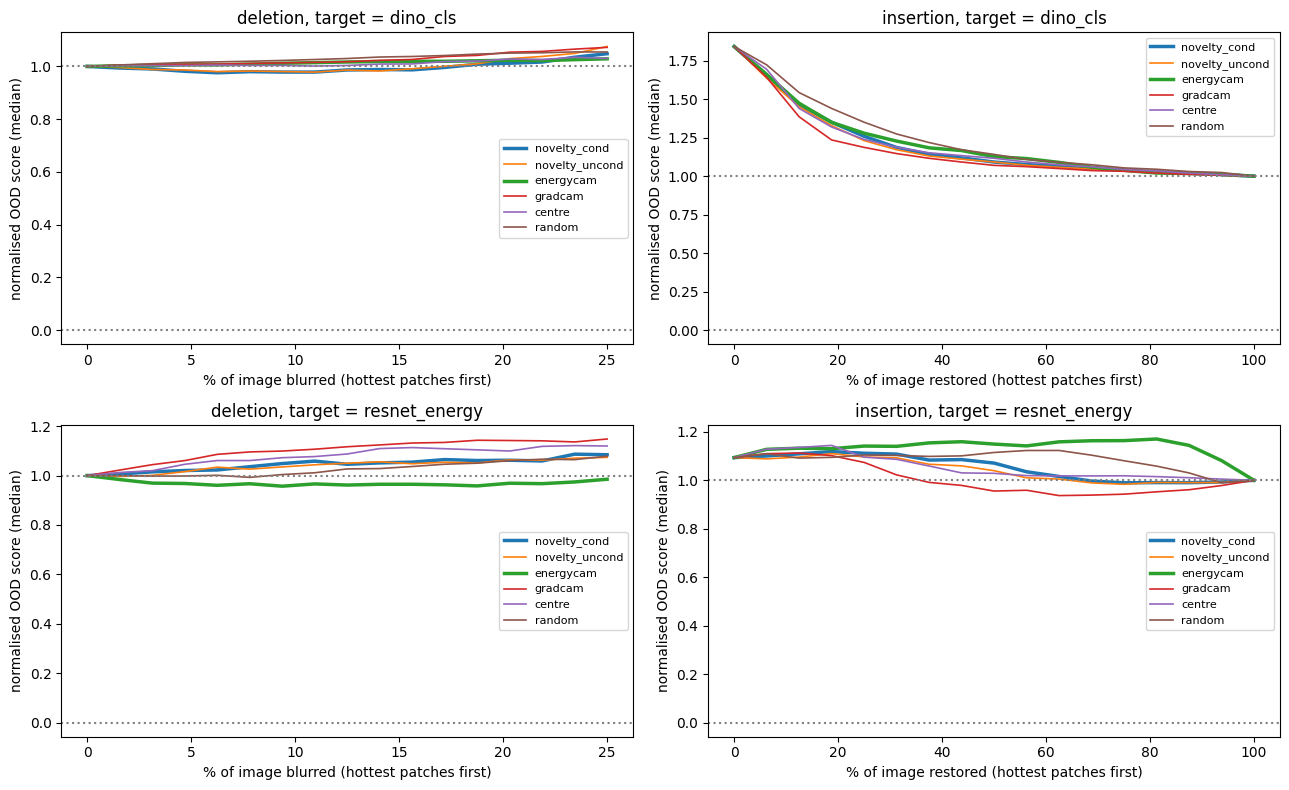

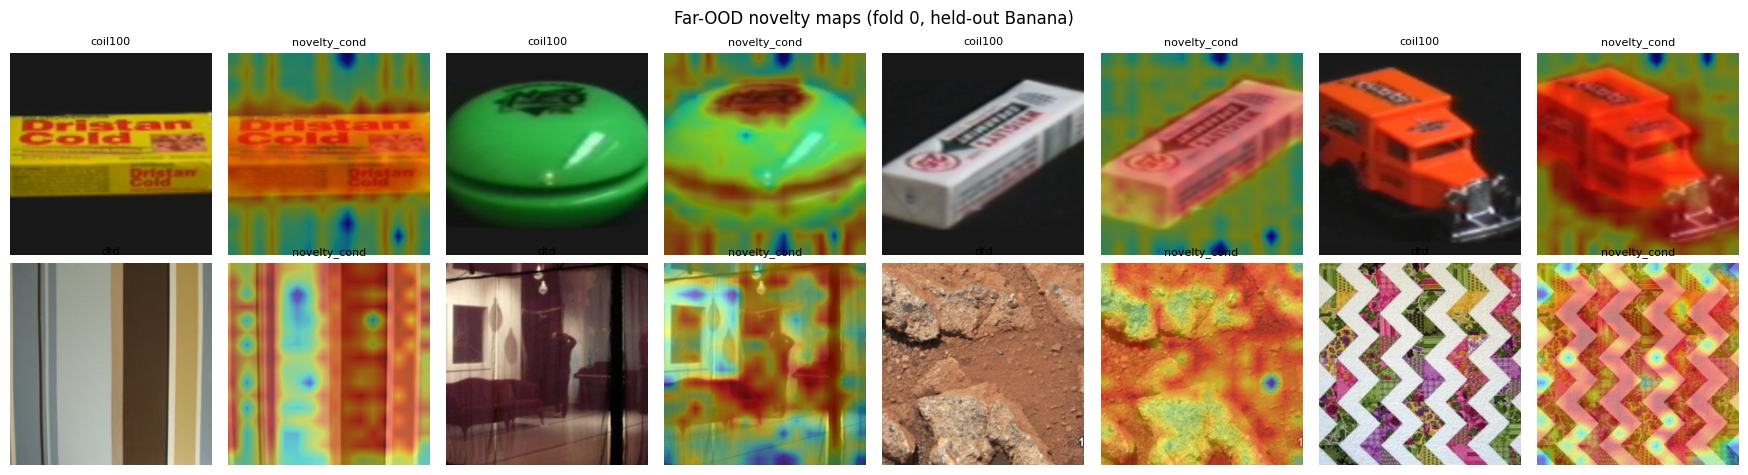

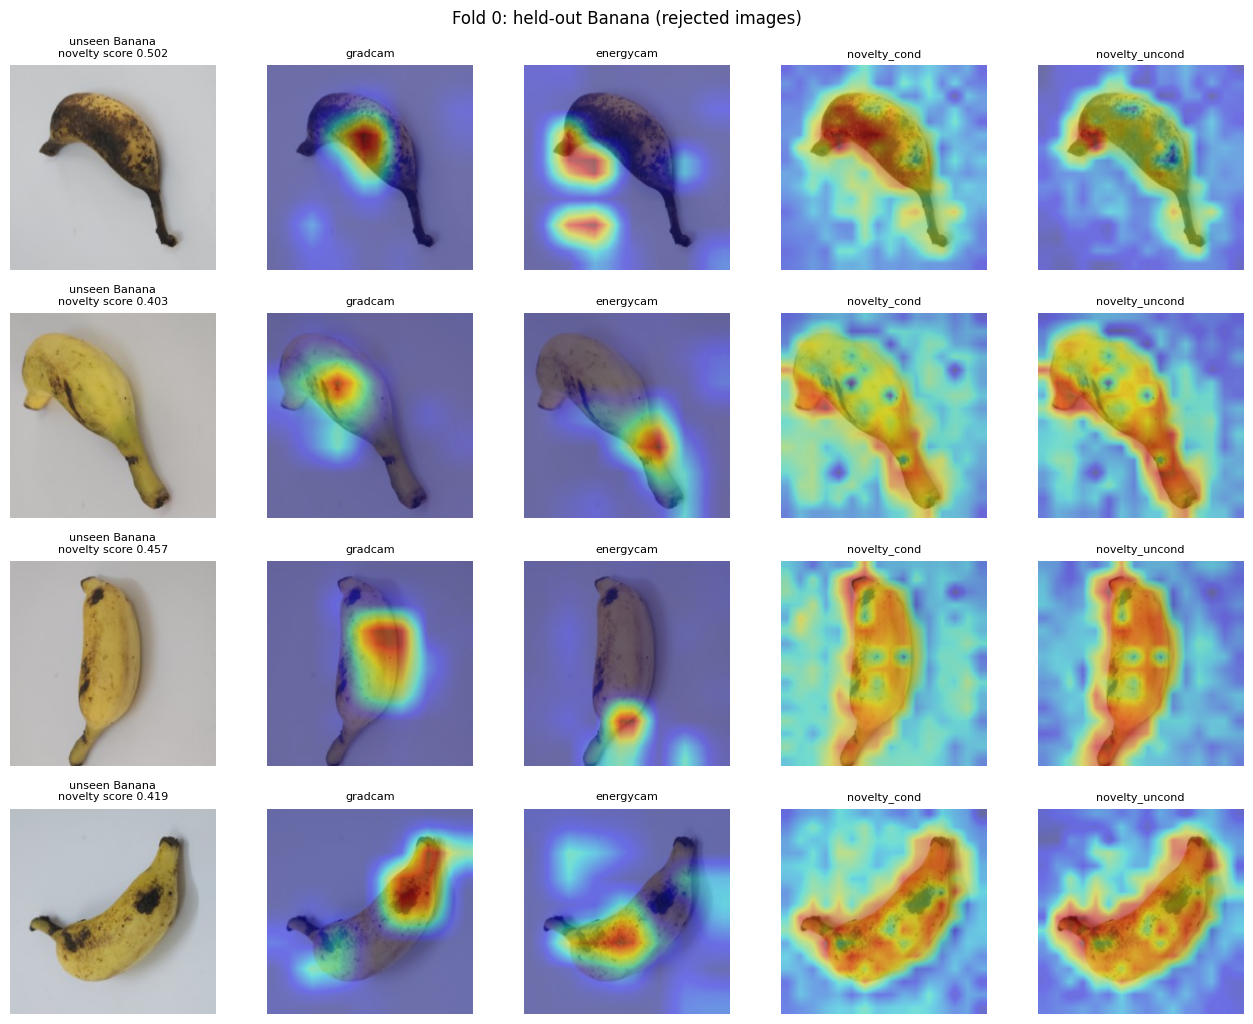

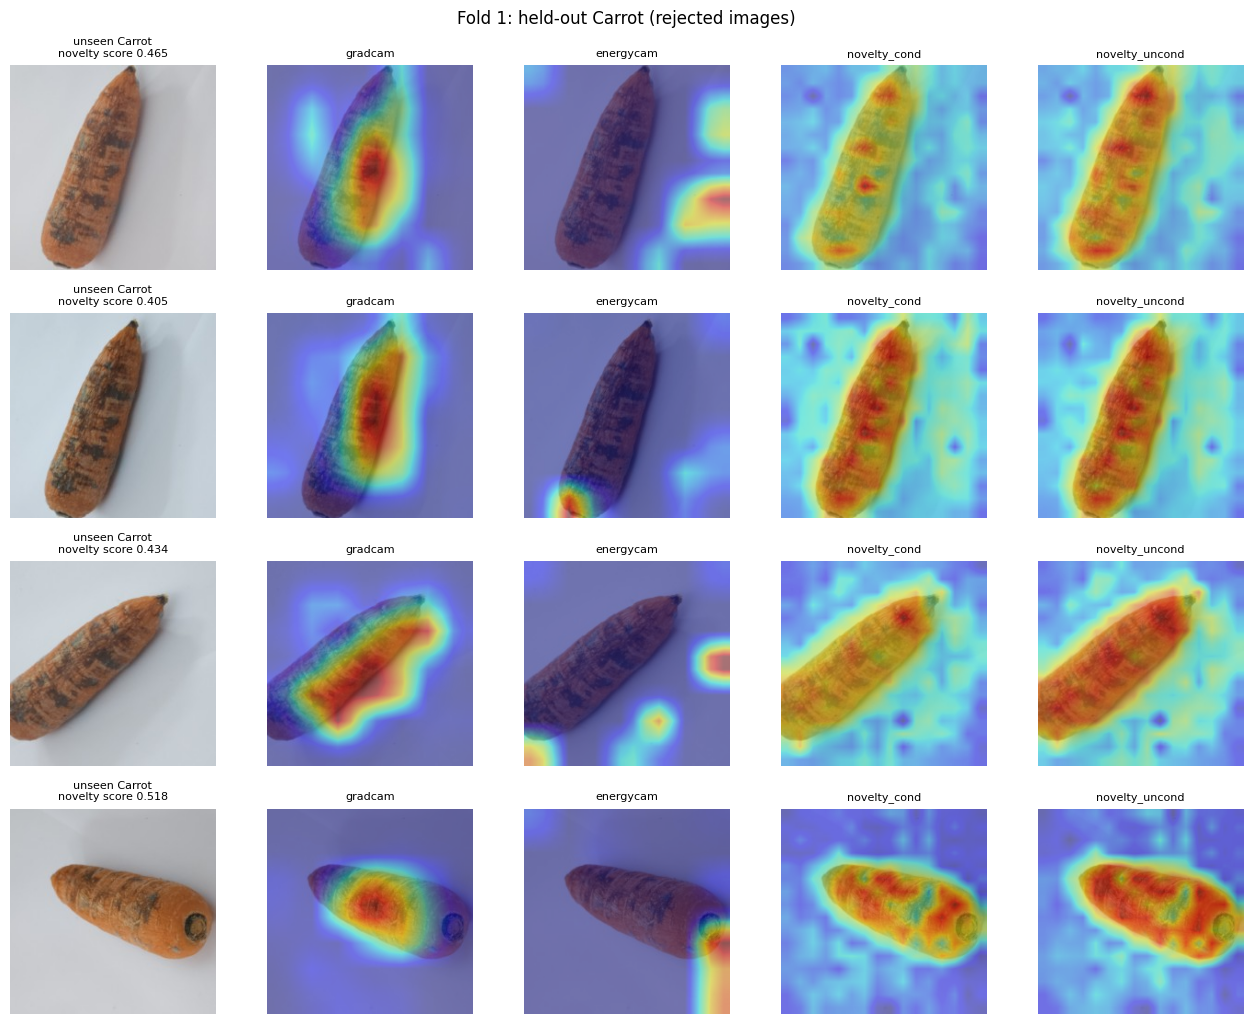

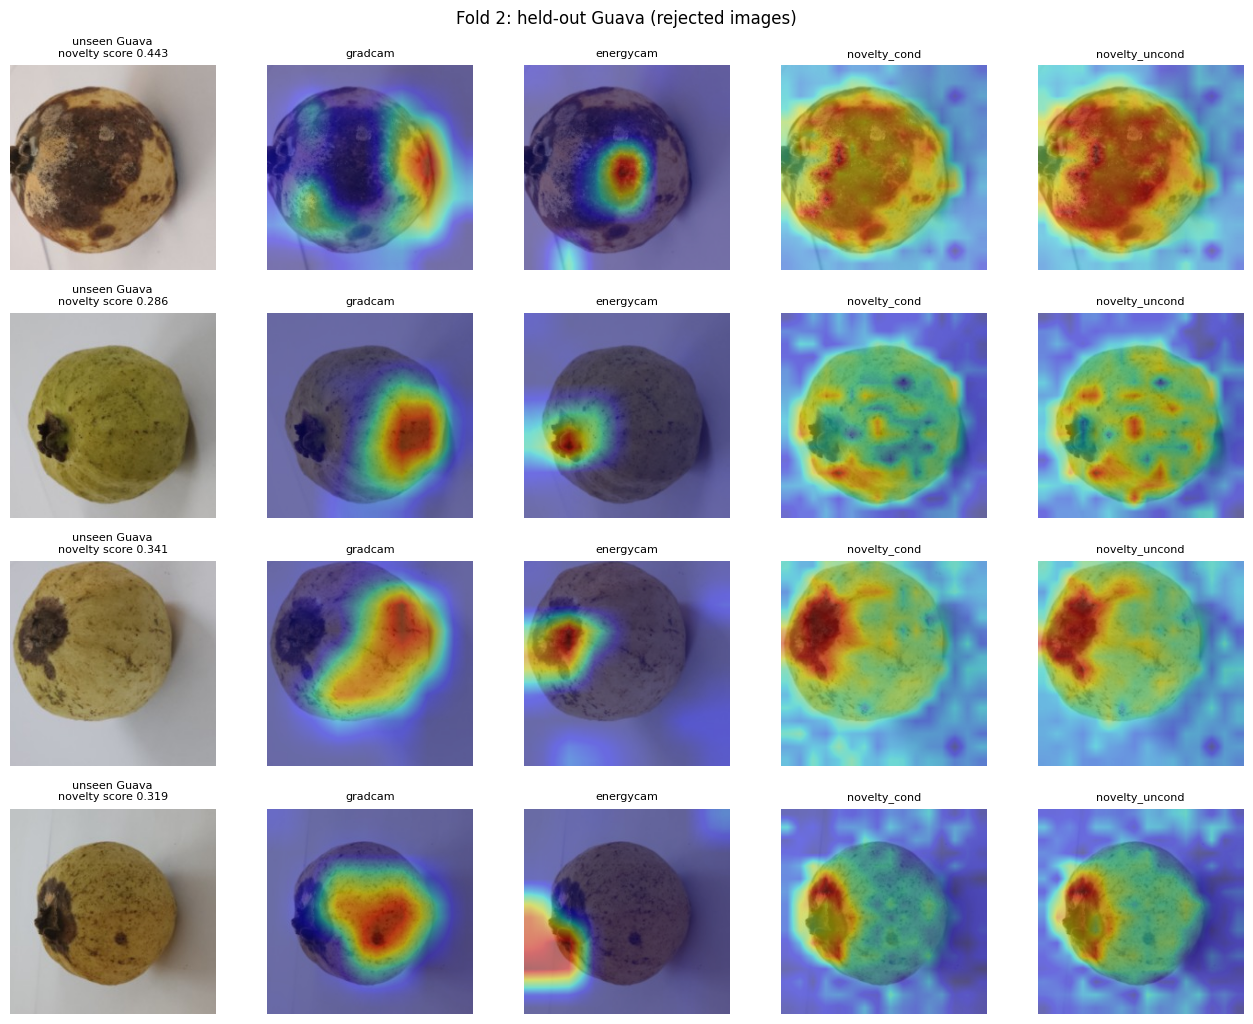

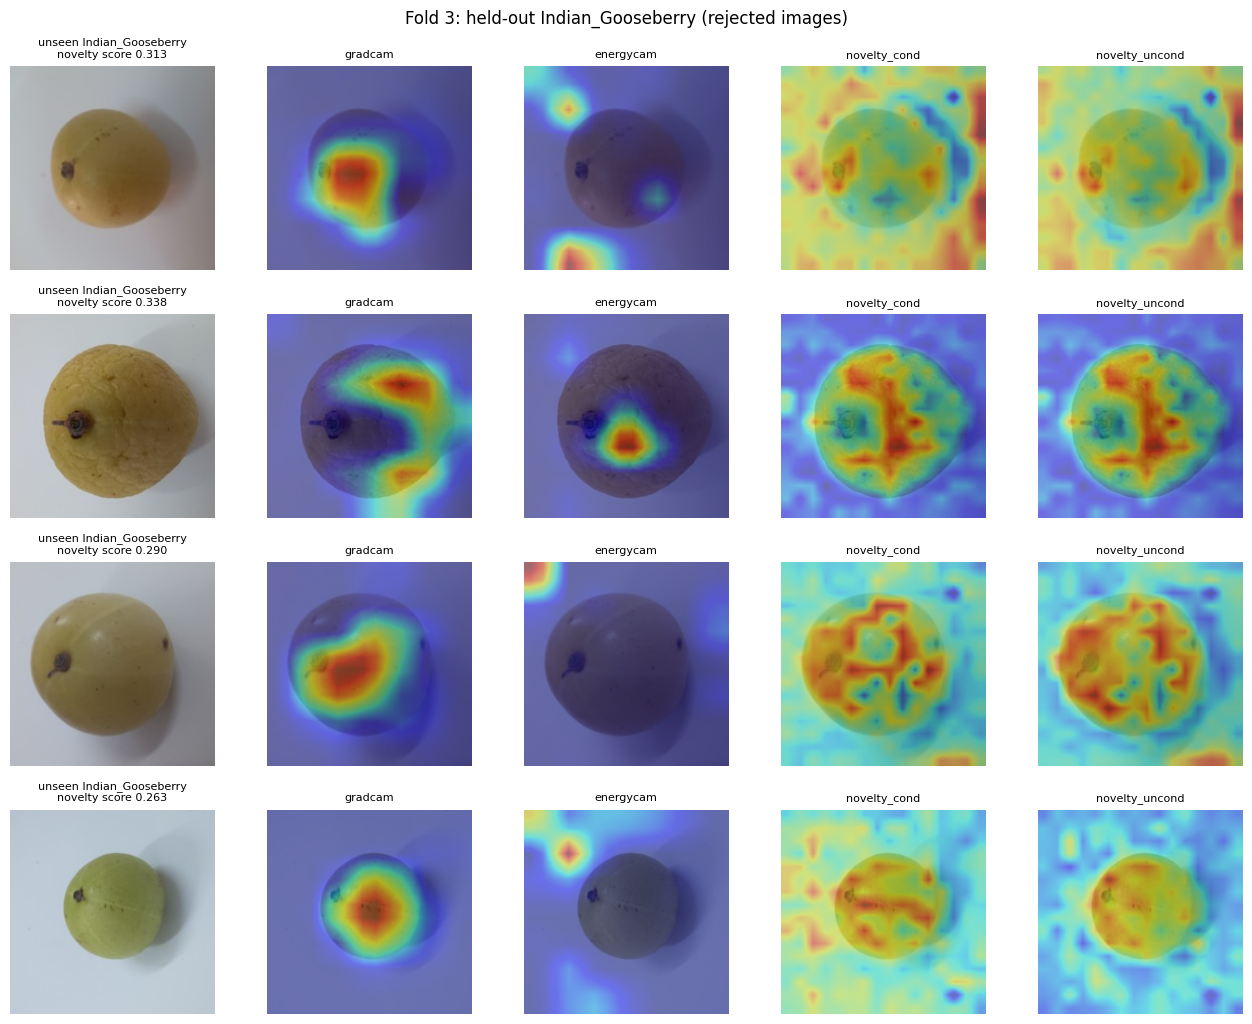

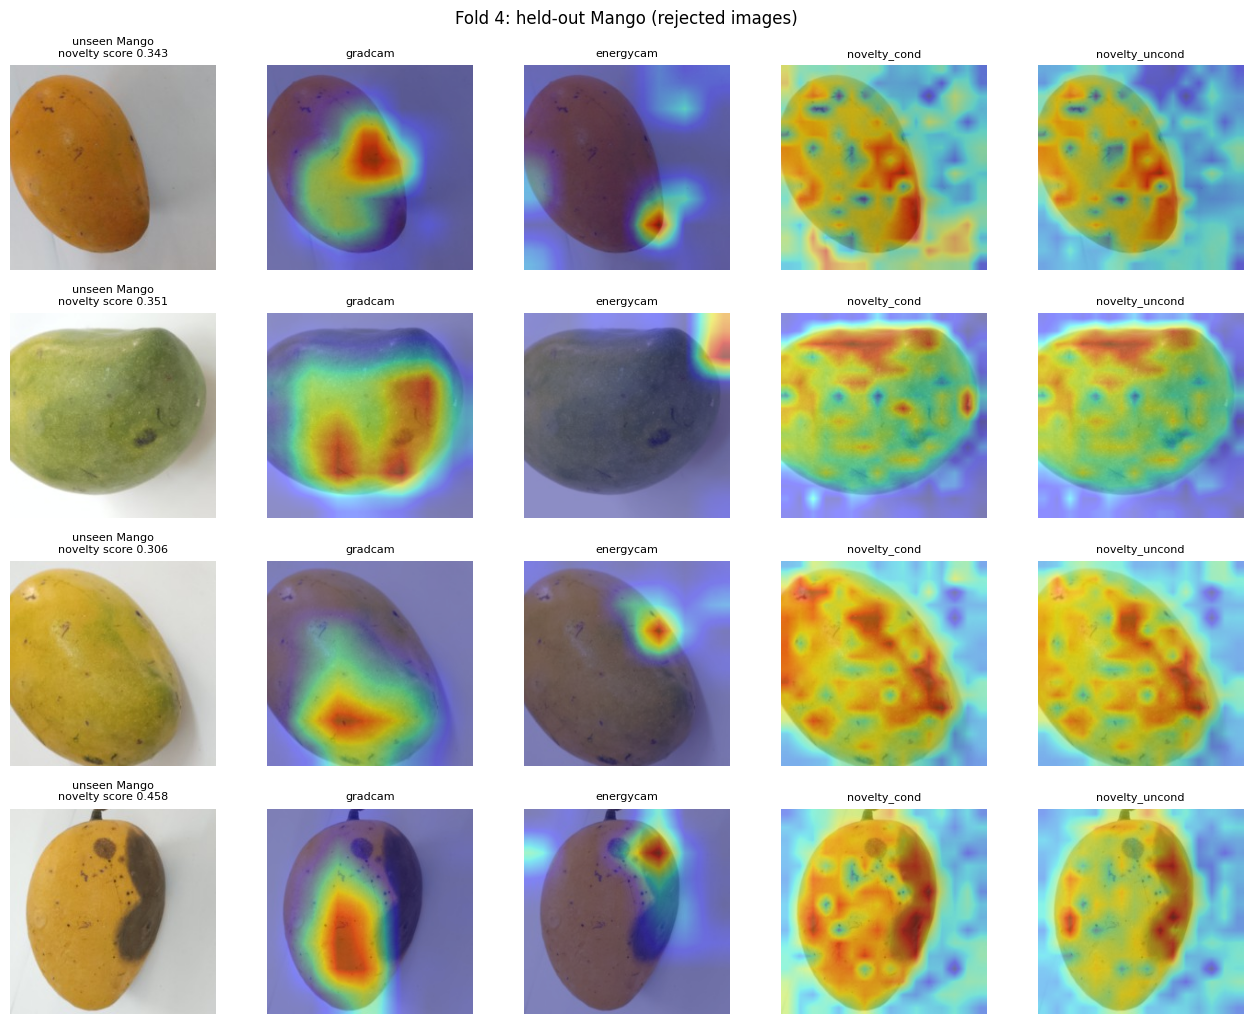

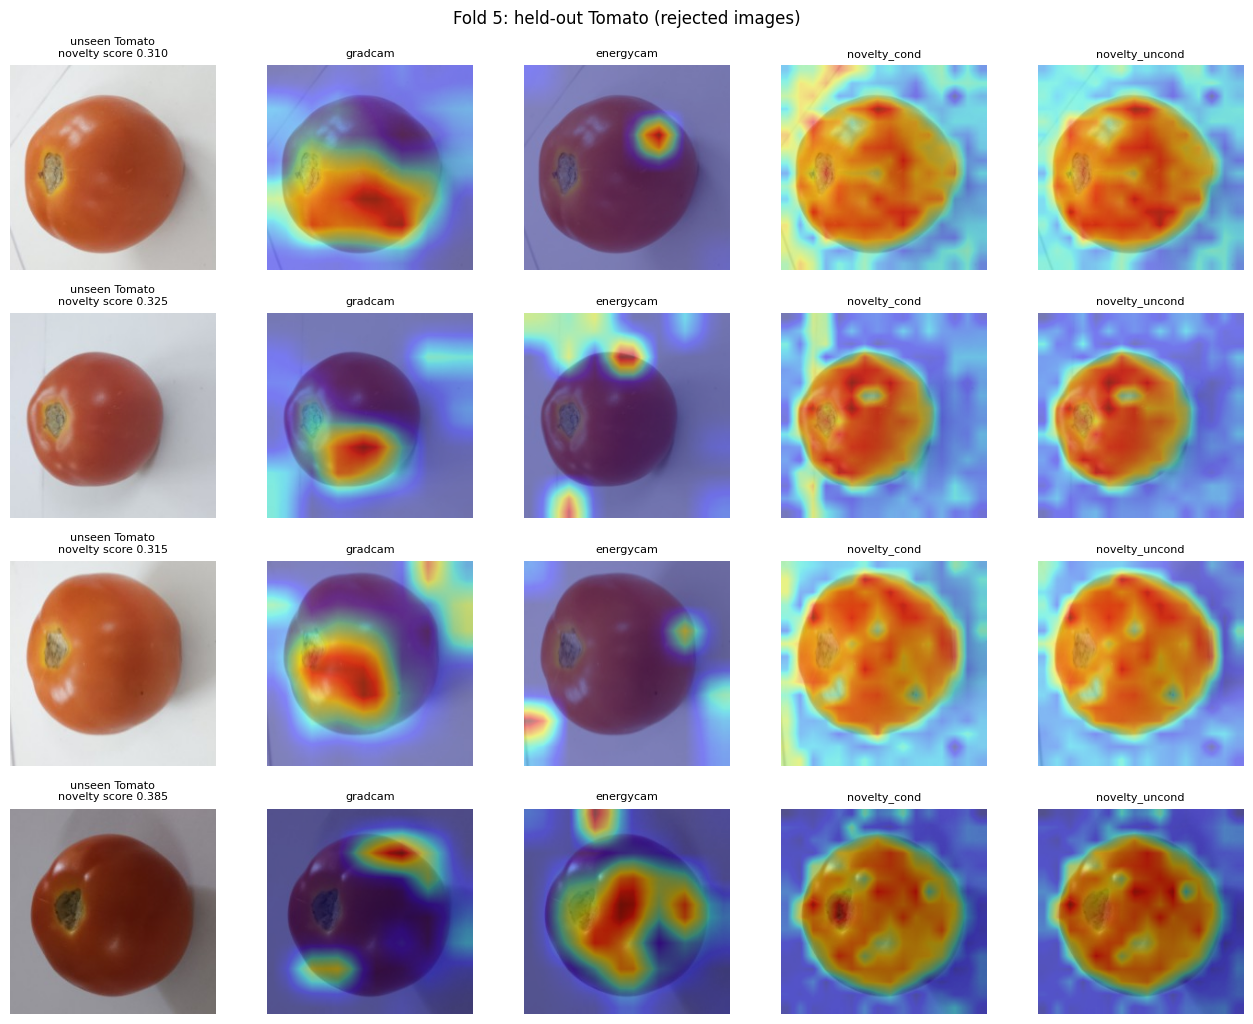

In [9]:
fig, axes = plt.subplots(len(set(faith.target)), 2, figsize=(13, 4 * len(set(faith.target))), squeeze=False)
for r, t in enumerate(sorted(set(faith.target))):
    for c, mode in enumerate(["deletion", "insertion"]):
        ax = axes[r, c]; x = np.array(STEPS[mode]) / (G * G) * 100
        for mname in ["novelty_cond", "novelty_uncond", "energycam", "gradcam", "centre", "random"]:
            cs = [cv for (tt, mm, nn, cv) in curves if tt == t and mm == mode and nn == mname]
            if cs:
                ax.plot(x, np.median(cs, 0), label=mname, lw=2.5 if mname in ("novelty_cond", "energycam") else 1.2)
        ax.axhline(0, color="grey", ls=":"); ax.axhline(1, color="grey", ls=":")
        ax.set_xlabel(f"% of image {'blurred' if mode == 'deletion' else 'restored'} (hottest patches first)")
        ax.set_ylabel("normalised OOD score (median)"); ax.set_title(f"{mode}, target = {t}"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "faithfulness_curves.png", dpi=200); plt.show()

def show(ax, img, heat=None, title=""):
    im = (img.permute(1, 2, 0) * torch.tensor(STD) + torch.tensor(MEAN)).clamp(0, 1).numpy()
    ax.imshow(im)
    if heat is not None:
        h = F.interpolate(heat[None, None].float(), size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
        h = (h - h.min()) / (h.max() - h.min() + 1e-12)
        ax.imshow(h.numpy(), cmap="jet", alpha=0.45)
    ax.set_title(title, fontsize=8); ax.axis("off")
if FOREIGN:
    z = np.load(OUT / f"novelty_maps_fold{FOLDS[0]}.npz")["foreign_cond"]
    srcs = list(FAR); ncol = 4
    fig, axes = plt.subplots(len(srcs), 2 * ncol, figsize=(2.2 * 2 * ncol, 2.4 * len(srcs)), squeeze=False)
    for r, src in enumerate(srcs):
        ids = np.where(FOREIGN_SRC == src)[0]
        ids = ids[np.linspace(0, len(ids) - 1, min(ncol, len(ids))).astype(int)]
        X = load_imgs([FOREIGN[i] for i in ids])
        for c in range(2 * ncol):
            axes[r, c].axis("off")
        for c, i in enumerate(ids):
            show(axes[r, 2 * c], X[c], title=src)
            show(axes[r, 2 * c + 1], X[c], torch.from_numpy(z[i].astype(np.float32)), "novelty_cond")
    plt.suptitle(f"Far-OOD novelty maps (fold {FOLDS[0]}, held-out {FOLD[FOLDS[0]]['held']})"); plt.tight_layout()
    plt.savefig(OUT / "maps_far_ood.png", dpi=200); plt.show()

for k, f, X, mp, sc in fig_items:
    cols = [m for m in ["gradcam", "energycam", "novelty_cond", "novelty_uncond"] if m in mp]
    fig, axes = plt.subplots(len(X), 1 + len(cols), figsize=(2.6 * (1 + len(cols)), 2.6 * len(X)), squeeze=False)
    for r in range(len(X)):
        show(axes[r, 0], X[r], title=f"unseen {f['held']}\nnovelty score {sc[r]:.3f}")
        for c, m in enumerate(cols):
            show(axes[r, c + 1], X[r], mp[m][r], m)
    plt.suptitle(f"Fold {k}: held-out {f['held']} (rejected images)"); plt.tight_layout()
    plt.savefig(OUT / f"maps_fold{k}.png", dpi=200); plt.show()

## 8. Triage: spoiled known produce vs unknown produce vs foreign objects

Runs only when `spoilage_labels.csv` is attached. Patch banks are rebuilt from **fresh (not spoiled) training produce only**, so spoilage is new to the model just like an unseen fruit is. One in five fresh training sessions is kept out of the bank to calibrate what a normal map looks like.

Groups scored: `known_fresh` and `known_spoiled` (validation and test days of the known classes), `unknown_fresh` and `unknown_spoiled` (the held-out class), and `foreign_<source>` (COIL-100, DTD, your photos). The hypothesis: spoilage lights up **small local spots**, an unknown fruit lights up **the whole fruit**, a foreign object lights up **everything that is not background**.

Images per group (summed over folds)


group
foreign_coil100    1800
foreign_dtd        1800
known_fresh        7400
known_spoiled      3400
unknown_fresh      3673
unknown_spoiled    1665
dtype: int64

Medians per group


,score_cls,score_cond,hot_frac,entropy
group,,,,
foreign_coil100,0.9090,0.8201,0.9961,0.9966
foreign_dtd,0.9449,0.8107,1.0000,0.9988
known_fresh,0.0592,0.1431,0.0039,0.8593
known_spoiled,0.2821,0.3548,0.2891,0.9487
unknown_fresh,0.5474,0.3481,0.6328,0.9774
unknown_spoiled,0.4356,0.3799,0.7617,0.9818


Pairwise AUROC (second group expected higher), mean over folds where both groups exist


metric,entropy,hot_frac,score_cls,score_cond
pair,,,,
known_fresh vs known_spoiled,0.8342,0.9427,0.9264,0.9613
known_spoiled vs foreign_coil100,0.9991,1.0000,0.9984,0.9999
known_spoiled vs foreign_dtd,1.0000,1.0000,0.9997,1.0000
known_spoiled vs unknown_fresh,0.9229,0.9263,0.8681,0.5663
known_spoiled vs unknown_spoiled,0.9305,0.9245,0.9101,0.6486
unknown_fresh vs foreign_coil100,0.9880,0.9949,0.9838,0.9985
unknown_fresh vs foreign_dtd,0.9991,0.9990,0.9978,0.9998
unknown_spoiled vs foreign_coil100,0.9913,0.9929,0.9850,0.9981
unknown_spoiled vs foreign_dtd,0.9996,0.9978,0.9980,0.9997


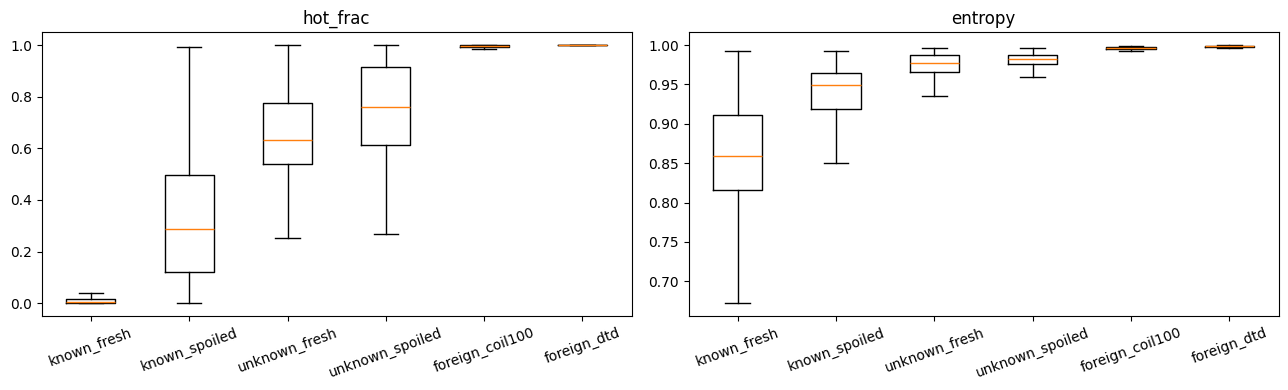

In [10]:
if SPOIL_CSV:
    trows = []
    for k in FOLDS:
        f = FOLD[k]
        fresh = f["train"][f["train"].spoil_status == "Not_spoiled"]
        sess = np.random.default_rng(SEED + k).permutation(fresh.session.unique())
        calib = set(sess[: max(1, len(sess) // 5)])
        bank_df, calib_df = fresh[~fresh.session.isin(calib)], fresh[fresh.session.isin(calib)]
        protos, banks = build_bank(bank_df, f["known"])
        cal = score_rows(calib_df.path, protos, banks)["map_cond"]
        tau, med = torch.quantile(cal.flatten(), 0.99).item(), cal.median().item()
        ev = pd.concat([f["val"], f["test"]])
        groups = {"known_fresh": ev[ev.spoil_status == "Not_spoiled"].path.tolist(),
                  "known_spoiled": ev[ev.spoil_status == "Spoiled"].path.tolist(),
                  "unknown_fresh": f["ood"][f["ood"].spoil_status == "Not_spoiled"].path.tolist(),
                  "unknown_spoiled": f["ood"][f["ood"].spoil_status == "Spoiled"].path.tolist(),
                  **{f"foreign_{src}": v for src, v in FAR.items()}}
        for gname, paths in groups.items():
            if not paths:
                continue
            Sg = score_rows(paths, protos, banks)
            hot, ent = spread(Sg["map_cond"], tau, med)
            for i, p in enumerate(paths):
                trows.append({"fold": k, "held_out": f["held"], "group": gname, "path": p, "score_cls": Sg["cls"][i].item(),
                              "score_cond": Sg["cond"][i].item(), "hot_frac": hot[i], "entropy": ent[i]})
        del banks
    tri = pd.DataFrame(trows); tri.to_csv(OUT / "triage_per_image.csv", index=False)
    print("Images per group (summed over folds)"); display(tri.groupby("group").size())
    print("Medians per group"); display(tri.groupby("group")[["score_cls", "score_cond", "hot_frac", "entropy"]].median().round(4))
    pairs = [("known_fresh", "known_spoiled"), ("known_spoiled", "unknown_fresh"), ("known_spoiled", "unknown_spoiled")]
    pairs += [(a, f"foreign_{src}") for src in FAR for a in ["known_spoiled", "unknown_fresh", "unknown_spoiled"]]
    prow = []
    for k in FOLDS:
        tk = tri[tri.fold == k]
        for a, b in pairs:
            A, B = tk[tk.group == a], tk[tk.group == b]
            if len(A) < 5 or len(B) < 5:
                continue
            for m in ["score_cls", "score_cond", "hot_frac", "entropy"]:
                prow.append({"fold": k, "pair": f"{a} vs {b}", "metric": m, "AUROC": auroc(A[m].values, B[m].values)})
    pa = pd.DataFrame(prow); pa.to_csv(OUT / "triage_pairwise_auroc.csv", index=False)
    print("Pairwise AUROC (second group expected higher), mean over folds where both groups exist")
    display(pa.pivot_table(index="pair", columns="metric", values="AUROC", aggfunc="mean").round(4))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    order = [g for g in ["known_fresh", "known_spoiled", "unknown_fresh", "unknown_spoiled"] + [f"foreign_{s}" for s in FAR] if g in set(tri.group)]
    for ax, m in zip(axes, ["hot_frac", "entropy"]):
        ax.boxplot([tri[tri.group == g][m] for g in order], showfliers=False)
        ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels(order, rotation=20)
        ax.set_title(m)
    plt.tight_layout(); plt.savefig(OUT / "triage_spread.png", dpi=200); plt.show()
else:
    print("spoilage_labels.csv not attached: triage skipped")

In [11]:
shutil.make_archive(str(OUT), "zip", OUT)
print("Download:", str(OUT) + ".zip")

Download: /kaggle/working/sentragrade_novelty.zip
